C:\Users\USER\anaconda3\envs\dl-ex01\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


TensorFlow: 2.15.1


100%|██████████| 331M/331M [01:47<00:00, 3.22MB/s] 

Extracting files...



Dataset downloaded to:
C:\Users\USER\.cache\kagglehub\datasets\jangedoo\utkface-new\versions\1

Dataset folders and files:
crop_part1
UTKFace
utkface_aligned_cropped

Number of images: 9780


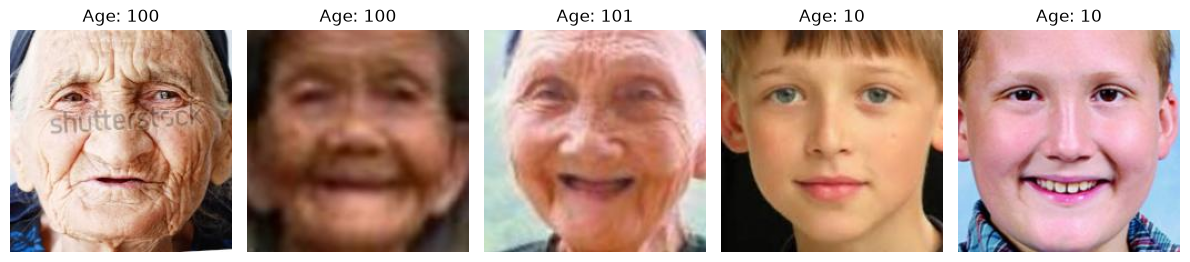

In [1]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub

from pathlib import Path
from PIL import Image

print("TensorFlow:", tf.__version__)

# Download UTKFace dataset
dataset_path = kagglehub.dataset_download("jangedoo/utkface-new")

print("\nDataset downloaded to:")
print(dataset_path)

# Explore downloaded folders
data_dir = Path(dataset_path)

print("\nDataset folders and files:")
for item in data_dir.iterdir():
    print(item.name)

# Use cropped face images
image_dir = data_dir / "crop_part1"

image_files = list(image_dir.glob("*.jpg"))

print("\nNumber of images:", len(image_files))

# Display sample images and their age labels
plt.figure(figsize=(12, 3))

for i, image_path in enumerate(image_files[:5]):
    image = Image.open(image_path)

    # Age is the first part of the filename
    age = image_path.name.split("_")[0]

    plt.subplot(1, 5, i + 1)
    plt.imshow(image)
    plt.title(f"Age: {age}")
    plt.axis("off")

plt.tight_layout()
plt.show()

Total valid images: 9780

Age Group Distribution:
age_group
Child          3255
Teenager        909
Young Adult    2551
Middle Aged    1613
Senior         1452
Name: count, dtype: int64


,image_path,age,age_group
0,C:\Users\USER\.cache\kagglehub\datasets\janged...,100,Senior
1,C:\Users\USER\.cache\kagglehub\datasets\janged...,100,Senior
2,C:\Users\USER\.cache\kagglehub\datasets\janged...,101,Senior
3,C:\Users\USER\.cache\kagglehub\datasets\janged...,10,Child
4,C:\Users\USER\.cache\kagglehub\datasets\janged...,10,Child


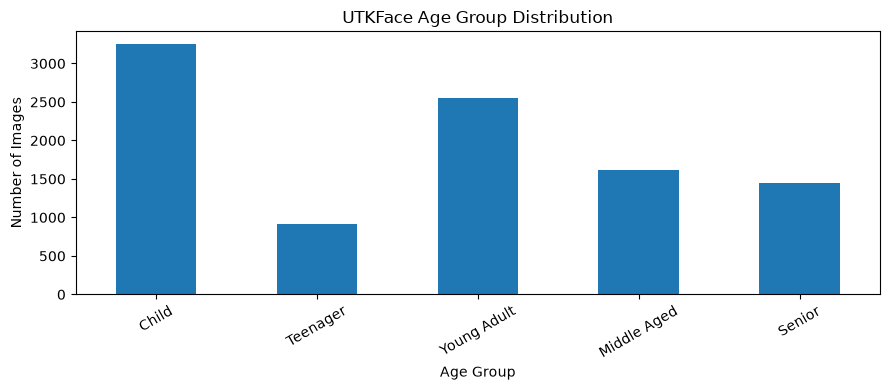

In [3]:
# Step 2: Create age group labels

age_data = []

for image_path in image_files:
    try:
        # Extract age from filename
        age = int(image_path.name.split("_")[0])

        # Keep valid age values
        if 0 <= age <= 120:
            age_data.append({
                "image_path": str(image_path),
                "age": age
            })

    except ValueError:
        continue

# Create DataFrame
age_df = pd.DataFrame(age_data)

# Convert ages into five groups
age_df["age_group"] = pd.cut(
    age_df["age"],
    bins=[-1, 12, 19, 39, 59, 120],
    labels=[
        "Child",
        "Teenager",
        "Young Adult",
        "Middle Aged",
        "Senior"
    ]
)

print("Total valid images:", len(age_df))

print("\nAge Group Distribution:")
print(age_df["age_group"].value_counts().sort_index())

display(age_df.head())

# Visualize distribution
plt.figure(figsize=(9, 4))
age_df["age_group"].value_counts().sort_index().plot(kind="bar")

plt.title("UTKFace Age Group Distribution")
plt.xlabel("Age Group")
plt.ylabel("Number of Images")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [11]:
from sklearn.model_selection import train_test_split

# First split: 85% training + validation, 15% testing
train_val_df, test_df = train_test_split(
    age_df,
    test_size=0.15,
    random_state=42,
    stratify=age_df["age_group"]
)

# Second split: 70% training, 15% validation
train_df, val_df = train_test_split(
    train_val_df,
    test_size=0.15 / 0.85,
    random_state=42,
    stratify=train_val_df["age_group"]
)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

print("\nTraining age-group distribution:")
print(train_df["age_group"].value_counts().sort_index())

print("\nValidation age-group distribution:")
print(val_df["age_group"].value_counts().sort_index())

print("\nTesting age-group distribution:")
print(test_df["age_group"].value_counts().sort_index())

Training images: 16594
Validation images: 3557
Testing images: 3557

Training age-group distribution:
age_group
Child          2389
Teenager        826
Young Adult    8316
Middle Aged    3180
Senior         1883
Name: count, dtype: int64

Validation age-group distribution:
age_group
Child           512
Teenager        177
Young Adult    1783
Middle Aged     682
Senior          403
Name: count, dtype: int64

Testing age-group distribution:
age_group
Child           512
Teenager        177
Young Adult    1782
Middle Aged     682
Senior          404
Name: count, dtype: int64


In [7]:
# Compare image counts in the three dataset folders

folders = [
    "crop_part1",
    "UTKFace",
    "utkface_aligned_cropped"
]

for folder in folders:
    folder_path = data_dir / folder

    if folder_path.exists():
        images = list(folder_path.rglob("*.jpg"))
        print(f"{folder}: {len(images)} images")
    else:
        print(f"{folder}: Folder not found")

crop_part1: 9780 images
UTKFace: 23708 images
utkface_aligned_cropped: 33488 images


In [9]:
# Use the larger UTKFace dataset
image_dir = data_dir / "UTKFace"

image_files = sorted(image_dir.rglob("*.jpg"))

age_data = []

for image_path in image_files:
    try:
        age = int(image_path.name.split("_")[0])

        if 0 <= age <= 116:
            age_data.append({
                "image_path": str(image_path),
                "age": age
            })

    except ValueError:
        continue

# Recreate our DataFrame
age_df = pd.DataFrame(age_data)

# Create age categories
age_df["age_group"] = pd.cut(
    age_df["age"],
    bins=[-1, 12, 19, 39, 59, 116],
    labels=[
        "Child",
        "Teenager",
        "Young Adult",
        "Middle Aged",
        "Senior"
    ]
)

print("Images found:", len(image_files))
print("Valid labelled images:", len(age_df))

print("\nAge group distribution:")
print(age_df["age_group"].value_counts().sort_index())

Images found: 23708
Valid labelled images: 23708

Age group distribution:
age_group
Child           3413
Teenager        1180
Young Adult    11881
Middle Aged     4544
Senior          2690
Name: count, dtype: int64


In [13]:
# Step 6: Image Preprocessing

IMG_SIZE = (64, 64)
BATCH_SIZE = 32

# Function to load and preprocess one image
def load_image(image_path, age):

    # Read the image
    image = tf.io.read_file(image_path)

    # Decode as RGB
    image = tf.io.decode_jpeg(image, channels=3)

    # Resize to 64x64
    image = tf.image.resize(image, IMG_SIZE)

    # Normalize pixel values to 0-1
    image = tf.cast(image, tf.float32) / 255.0

    return image, tf.cast(age, tf.float32)


# Function to build our TensorFlow dataset
def make_dataset(df, training=False):

    paths = df["image_path"].to_numpy()
    ages = df["age"].to_numpy(dtype="float32")

    ds = tf.data.Dataset.from_tensor_slices((paths, ages))

    # Shuffle training images only
    if training:
        ds = ds.shuffle(
            buffer_size=len(df),
            seed=42
        )

    # Preprocess each image
    ds = ds.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    # Create batches
    ds = ds.batch(BATCH_SIZE)

    # Improve loading efficiency
    ds = ds.prefetch(tf.data.AUTOTUNE)

    return ds


# Create our datasets
train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

# Check one batch
for images, ages in train_ds.take(1):

    print("Image batch shape:", images.shape)
    print("Age batch shape:", ages.shape)

    print("Pixel range:",
          float(tf.reduce_min(images)),
          "to",
          float(tf.reduce_max(images)))

    print("First 5 ages:", ages[:5].numpy())

Image batch shape: (32, 64, 64, 3)
Age batch shape: (32,)
Pixel range: 0.0 to 1.0
First 5 ages: [15. 46. 52.  1. 21.]


In [15]:
# Step 7: Build the Age Prediction CNN

from tensorflow.keras import layers, models

tf.keras.utils.set_random_seed(42)

age_cnn = models.Sequential([

    # Input: 64x64 RGB image
    layers.Input(shape=(64, 64, 3)),

    # Data augmentation
    layers.RandomFlip("horizontal"),

    # Convolution Block 1
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Convolution Block 2
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Convolution Block 3
    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Regression layers
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),

    # Output: One predicted age
    layers.Dense(1, activation="linear")

])

# Compile the model
age_cnn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss=tf.keras.losses.Huber(delta=10.0),
    metrics=["mae"]
)

# Display model architecture
age_cnn.summary()

print("\nAge Prediction CNN initialized successfully!")



Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 random_flip (RandomFlip)    (None, 64, 64, 3)         0         
                                                                 
 conv2d (Conv2D)             (None, 64, 64, 32)        896       
                                                                 
 max_pooling2d (MaxPooling2  (None, 32, 32, 32)        0         
 D)                                                              
                                                                 
 conv2d_1 (Conv2D)           (None, 32, 32, 64)        18496     
                                                                 
 max_pooling2d_1 (MaxPoolin  (None, 16, 16, 64)        0         
 g2D)                                                            
                                                                 
 conv2d_2 (Conv2D)           (None, 16, 16, 128)      

In [17]:
# Step 8: Train the Age Prediction CNN

from tensorflow.keras.callbacks import EarlyStopping

# Configure Early Stopping
early_stop_age = EarlyStopping(
    monitor="val_mae",
    patience=4,
    min_delta=0.1,
    mode="min",
    restore_best_weights=True
)

# Train the CNN
history_age = age_cnn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[early_stop_age],
    verbose=1
)

# Find the best epoch
best_epoch = np.argmin(history_age.history["val_mae"]) + 1

# Evaluate on validation data
val_loss, val_mae = age_cnn.evaluate(val_ds, verbose=0)

# Save trained CNN
age_cnn.save("utkface_age_cnn.keras")

print("\nAge Prediction CNN trained successfully!")
print("Epochs completed:", len(history_age.history["loss"]))
print("Best epoch:", best_epoch)
print("Validation MAE:", round(val_mae, 2), "years")
print("Model saved as utkface_age_cnn.keras")

Epoch 1/20


519/519 [==============================] - 109s 205ms/step - loss: 99.7168 - mae: 14.0814 - val_loss: 78.1428 - val_mae: 11.9236
Epoch 2/20
519/519 [==============================] - 59s 114ms/step - loss: 66.0723 - mae: 10.4381 - val_loss: 51.9865 - val_mae: 8.7916
Epoch 3/20
519/519 [==============================] - 59s 114ms/step - loss: 53.9129 - mae: 9.0355 - val_loss: 44.6631 - val_mae: 7.9029
Epoch 4/20
519/519 [==============================] - 59s 114ms/step - loss: 48.4813 - mae: 8.4047 - val_loss: 48.6588 - val_mae: 8.2769
Epoch 5/20
519/519 [==============================] - 60s 115ms/step - loss: 44.3208 - mae: 7.9266 - val_loss: 37.4326 - val_mae: 7.1492
Epoch 6/20
519/519 [==============================] - 59s 114ms/step - loss: 41.7334 - mae: 7.6118 - val_loss: 35.4585 - val_mae: 6.8377
Epoch 7/20
519/519 [==============================] - 58s 112ms/step - loss: 39.6606 - mae: 7.3517 - val_loss: 35.0572 - val_mae: 6.8222
Epoch 8/20
519/519 [===============

In [19]:
# Step 9: Evaluate the CNN on unseen test images

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    accuracy_score
)

# Load the saved model if the notebook kernel was restarted
if "age_cnn" not in globals():
    age_cnn = tf.keras.models.load_model("utkface_age_cnn.keras")

# 1. Evaluate test performance
test_loss, test_mae = age_cnn.evaluate(test_ds, verbose=0)

print("CNN TEST RESULTS")
print("Test MAE:", round(test_mae, 2), "years")


# 2. Predict numerical ages
predicted_ages = age_cnn.predict(
    test_ds,
    verbose=1
).flatten()

# Actual ages (same order as our unshuffled test_ds)
actual_ages = test_df["age"].to_numpy()

# Calculate RMSE
test_rmse = np.sqrt(
    mean_squared_error(actual_ages, predicted_ages)
)

print("Test RMSE:", round(test_rmse, 2), "years")


# 3. Round predicted ages and keep them within 0-116
predicted_years = np.clip(
    np.rint(predicted_ages), 0, 116
).astype(int)


# 4. Convert ages into categories
def get_age_category(age):
    if age <= 12:
        return "Child"
    elif age <= 19:
        return "Teenager"
    elif age <= 39:
        return "Young Adult"
    elif age <= 59:
        return "Middle Aged"
    else:
        return "Senior"


actual_groups = [
    get_age_category(age) for age in actual_ages
]

predicted_groups = [
    get_age_category(age) for age in predicted_years
]


# 5. Calculate age-group accuracy
group_accuracy = accuracy_score(
    actual_groups,
    predicted_groups
)

print("Age Group Accuracy:",
      round(group_accuracy * 100, 2), "%")


# 6. Compare actual and predicted ages
results_df = pd.DataFrame({
    "Actual Age": actual_ages,
    "Predicted Age": predicted_years,
    "Actual Category": actual_groups,
    "Predicted Category": predicted_groups,
    "Absolute Error": np.abs(actual_ages - predicted_ages)
})

print("\nFirst 10 Predictions:")
display(results_df.head(10))

CNN TEST RESULTS
Test MAE: 6.54 years
112/112 [==============================] - 5s 38ms/step
Test RMSE: 9.04 years
Age Group Accuracy: 73.15 %

First 10 Predictions:


,Actual Age,Predicted Age,Actual Category,Predicted Category,Absolute Error
0,44,35,Middle Aged,Young Adult,8.931210
1,49,37,Middle Aged,Young Adult,12.283825
2,40,40,Middle Aged,Middle Aged,0.335285
3,26,41,Young Adult,Middle Aged,15.022999
4,24,31,Young Adult,Young Adult,6.936607
5,26,30,Young Adult,Young Adult,3.958147
6,19,17,Teenager,Teenager,2.176876
7,22,21,Young Adult,Young Adult,1.389120
8,60,79,Senior,Senior,19.270592
9,1,1,Child,Child,0.073321


AGE GROUP CLASSIFICATION REPORT
              precision    recall  f1-score   support

       Child       0.97      0.76      0.85       512
    Teenager       0.26      0.25      0.26       177
 Young Adult       0.80      0.85      0.83      1782
 Middle Aged       0.53      0.58      0.55       682
      Senior       0.72      0.65      0.68       404

    accuracy                           0.73      3557
   macro avg       0.66      0.62      0.63      3557
weighted avg       0.74      0.73      0.73      3557



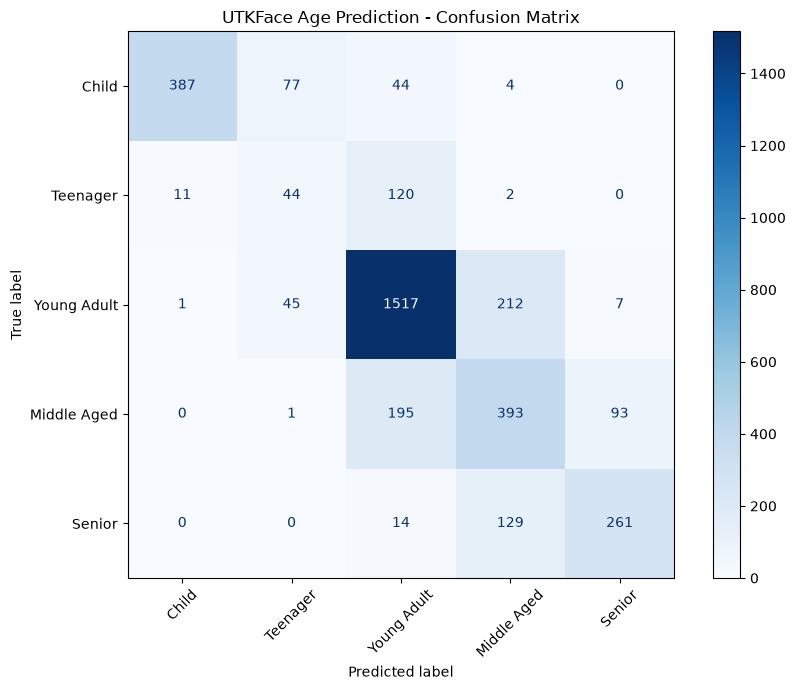

In [21]:
# Step 10: Age Group Classification Report and Confusion Matrix

from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Define age groups in the correct order
group_names = [
    "Child",
    "Teenager",
    "Young Adult",
    "Middle Aged",
    "Senior"
]

# Classification report
print("AGE GROUP CLASSIFICATION REPORT")

print(classification_report(
    actual_groups,
    predicted_groups,
    labels=group_names,
    zero_division=0
))

# Confusion matrix
fig, ax = plt.subplots(figsize=(9, 7))

ConfusionMatrixDisplay.from_predictions(
    actual_groups,
    predicted_groups,
    labels=group_names,
    cmap="Blues",
    values_format="d",
    xticks_rotation=45,
    ax=ax
)

plt.title("UTKFace Age Prediction - Confusion Matrix")
plt.tight_layout()
plt.show()

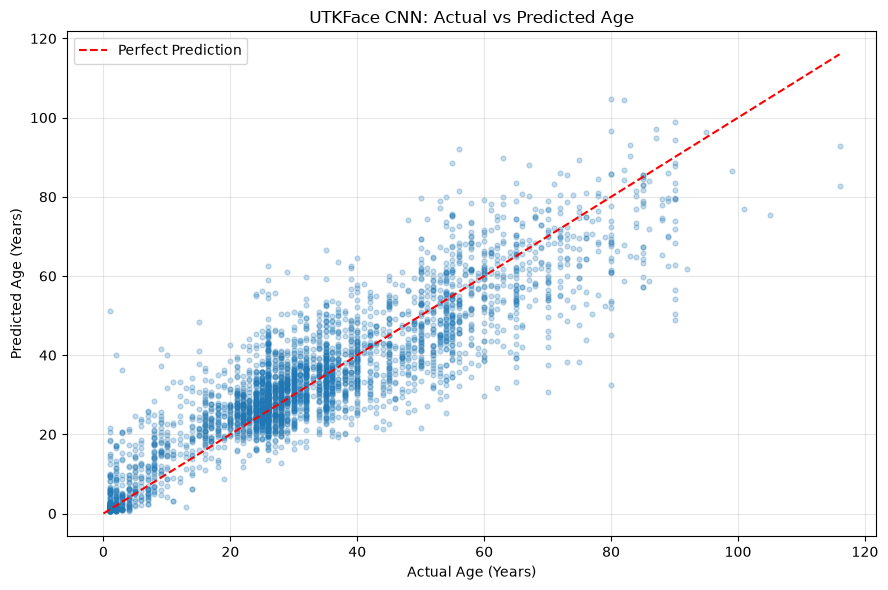

Mean Absolute Error by Age Group:
Age Group
Child           4.48
Young Adult     5.41
Teenager        7.33
Middle Aged     8.26
Senior         10.92
Name: Absolute Error, dtype: float64


In [23]:
# Step 11: Actual Age vs Predicted Age

plt.figure(figsize=(9, 6))

# Plot every test prediction
plt.scatter(
    actual_ages,
    predicted_ages,
    alpha=0.25,
    s=12
)

# Perfect prediction reference line
plt.plot(
    [0, 116],
    [0, 116],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Age (Years)")
plt.ylabel("Predicted Age (Years)")
plt.title("UTKFace CNN: Actual vs Predicted Age")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# Check average error for each actual age group
error_df = pd.DataFrame({
    "Age Group": actual_groups,
    "Absolute Error": np.abs(actual_ages - predicted_ages)
})

print("Mean Absolute Error by Age Group:")
print(
    error_df.groupby("Age Group")["Absolute Error"]
    .mean()
    .round(2)
    .sort_values()
)

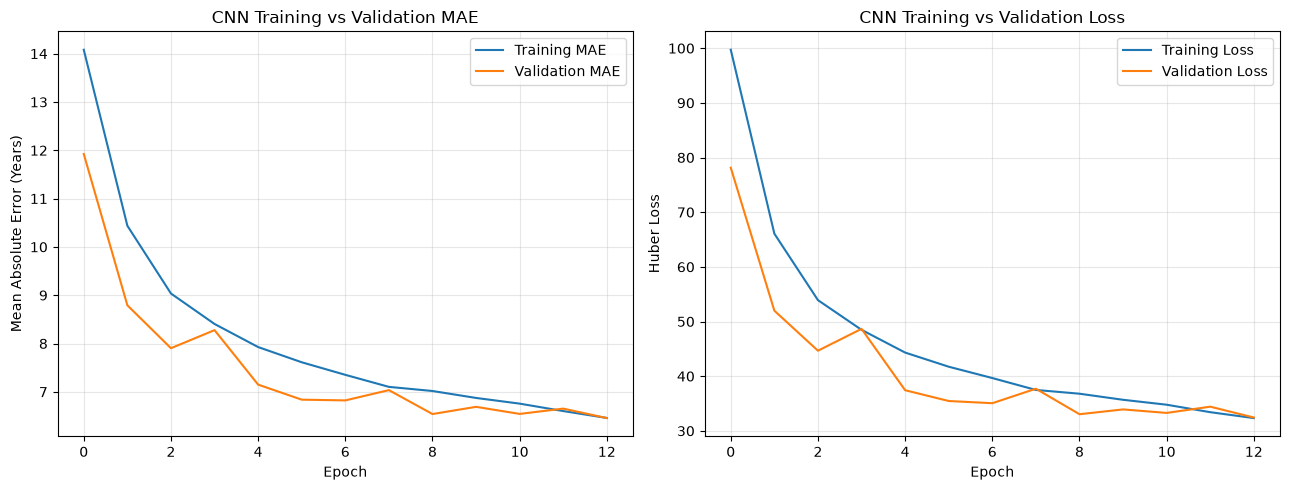


Mean Absolute Error by Age Group:


,mean,count
Age Group,,
Child,4.48,512
Young Adult,5.41,1782
Teenager,7.33,177
Middle Aged,8.26,682
Senior,10.92,404


In [25]:
# Step 12: Visualize CNN Training History

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Graph 1: Training MAE vs Validation MAE
axes[0].plot(
    history_age.history["mae"],
    label="Training MAE"
)

axes[0].plot(
    history_age.history["val_mae"],
    label="Validation MAE"
)

axes[0].set_title("CNN Training vs Validation MAE")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Mean Absolute Error (Years)")
axes[0].legend()
axes[0].grid(alpha=0.3)


# Graph 2: Training Loss vs Validation Loss
axes[1].plot(
    history_age.history["loss"],
    label="Training Loss"
)

axes[1].plot(
    history_age.history["val_loss"],
    label="Validation Loss"
)

axes[1].set_title("CNN Training vs Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Huber Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


# Show MAE for each age group
print("\nMean Absolute Error by Age Group:")

display(
    error_df.groupby("Age Group")["Absolute Error"]
    .agg(["mean", "count"])
    .round(2)
    .sort_values("mean")
)

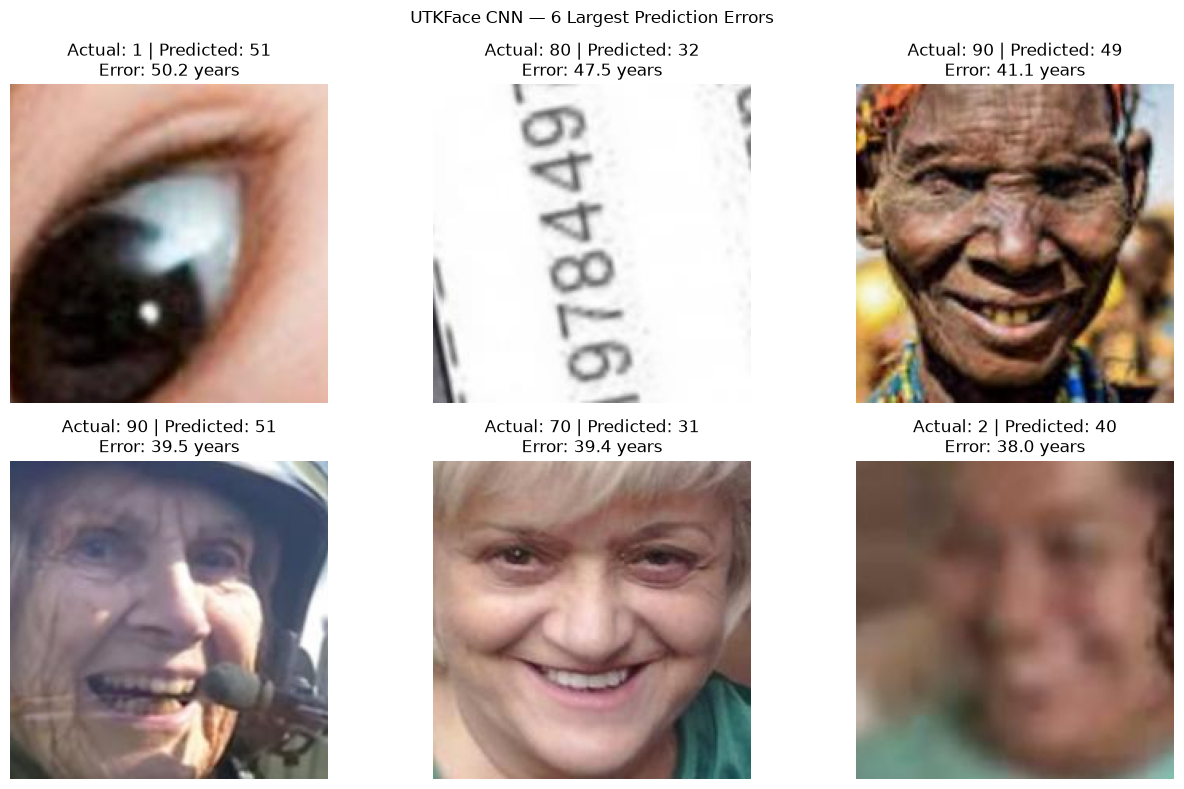

AVERAGE AGE ERROR BY CATEGORY


,mean,count
Age Group,,
Child,4.48,512
Young Adult,5.41,1782
Teenager,7.33,177
Middle Aged,8.26,682
Senior,10.92,404


In [27]:
# Step 13: Analyze the CNN's prediction errors

# Calculate absolute errors for all test images
absolute_errors = np.abs(actual_ages - predicted_ages)

# Find the 6 images with the largest errors
worst_indices = np.argsort(absolute_errors)[-6:][::-1]

plt.figure(figsize=(13, 8))

for i, idx in enumerate(worst_indices):

    # Get the image path
    image_path = test_df.iloc[idx]["image_path"]

    # Open the image
    image = Image.open(image_path).convert("RGB")

    # Actual and predicted ages
    actual = int(actual_ages[idx])
    predicted = int(np.rint(predicted_ages[idx]))

    # Display image
    plt.subplot(2, 3, i + 1)
    plt.imshow(image)

    plt.title(
        f"Actual: {actual} | Predicted: {predicted}\n"
        f"Error: {absolute_errors[idx]:.1f} years"
    )

    plt.axis("off")

plt.suptitle("UTKFace CNN — 6 Largest Prediction Errors")
plt.tight_layout()
plt.show()


# Display average error for each age group
print("AVERAGE AGE ERROR BY CATEGORY")

display(
    error_df.groupby("Age Group")["Absolute Error"]
    .agg(["mean", "count"])
    .round(2)
    .sort_values("mean")
)

In [29]:
# Save our trained UTKFace CNN in H5 format
age_cnn.save("utkface_age_cnn.h5", include_optimizer=False)

# Verify that the model can be loaded
test_model = tf.keras.models.load_model(
    "utkface_age_cnn.h5",
    compile=False
)

print("Age Prediction CNN exported successfully!")

C:\Users\USER\anaconda3\envs\dl-ex01\Lib\site-packages\keras\src\engine\training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


Age Prediction CNN exported successfully!


In [39]:

%%writefile streamlit_app.py

import streamlit as st
import tensorflow as tf
import numpy as np
import cv2
from PIL import Image
from pathlib import Path

# --------------------------------------------------
# 1. Page Configuration
# --------------------------------------------------

st.set_page_config(
    page_title="AgeVision",
    page_icon="🎂",
    layout="wide"
)

# --------------------------------------------------
# 2. Load CNN Model and Face Detector
# --------------------------------------------------

@st.cache_resource
def load_resources():

    model_path = Path(__file__).resolve().parent / "utkface_age_cnn.h5"

    model = tf.keras.models.load_model(
        model_path,
        compile=False
    )

    detector = cv2.CascadeClassifier(
        cv2.data.haarcascades
        + "haarcascade_frontalface_default.xml"
    )

    if detector.empty():
        raise RuntimeError("Face detector could not be loaded.")

    return model, detector


model, detector = load_resources()


# --------------------------------------------------
# 3. Convert Predicted Age to Age Category
# --------------------------------------------------

def get_age_category(age):

    if age <= 12:
        return "Child"

    elif age <= 19:
        return "Teenager"

    elif age <= 39:
        return "Young Adult"

    elif age <= 59:
        return "Middle Aged"

    else:
        return "Senior"


# --------------------------------------------------
# 4. Application Interface
# --------------------------------------------------

st.title("🎂 AgeVision")

st.subheader(
    "AI-Powered Age Estimation Using Deep Learning"
)

st.write(
    "Upload a face image or capture a webcam photo "
    "to estimate the person's age and age category."
)

# Sidebar
st.sidebar.header("About AgeVision")

st.sidebar.write("Dataset: UTKFace")

st.sidebar.write(
    "Architecture: Convolutional Neural Network"
)

st.sidebar.metric(
    "Test MAE",
    "6.54 years"
)

st.sidebar.metric(
    "Age Group Accuracy",
    "73.15%"
)

# --------------------------------------------------
# 5. Choose Image Input Method
# --------------------------------------------------

mode = st.radio(
    "Choose your input method",
    ["Upload Image", "Use Webcam"],
    horizontal=True
)

if mode == "Upload Image":

    uploaded = st.file_uploader(
        "Upload a face image",
        type=["jpg", "jpeg", "png"]
    )

else:

    uploaded = st.camera_input(
        "Take a photo"
    )


# --------------------------------------------------
# 6. Process Image
# --------------------------------------------------

if uploaded is not None:

    # Open image and convert to RGB
    image = Image.open(uploaded).convert("RGB")

    rgb = np.array(image)

    # Determine whether to skip face detection
    use_full_image = False

    if mode == "Upload Image":

        use_full_image = st.checkbox(
            "This image is already cropped (UTKFace test image)"
        )

    # Option A: Already cropped image
    if use_full_image:

        face = rgb

        st.info(
            "Using the entire image for age prediction."
        )

    # Option B: Detect face with OpenCV
    else:

        gray = cv2.cvtColor(
            rgb,
            cv2.COLOR_RGB2GRAY
        )

        faces = detector.detectMultiScale(
            gray,
            scaleFactor=1.1,
            minNeighbors=5,
            minSize=(30, 30)
        )

        if len(faces) == 0:

            st.warning(
                "No face detected. "
                "Try a clearer, front-facing photo. "
                "For an already-cropped UTKFace image, "
                "select the cropped-image checkbox."
            )

            st.stop()

        # Select the largest detected face
        x, y, w, h = max(
            faces,
            key=lambda f: f[2] * f[3]
        )

        # Crop the selected face
        face = rgb[y:y+h, x:x+w]


    # --------------------------------------------------
    # 7. Prepare Image for Our CNN
    # --------------------------------------------------

    # Resize to 64 x 64
    face_resized = cv2.resize(
        face,
        (64, 64),
        interpolation=cv2.INTER_LINEAR
    )

    # Normalize pixel values between 0 and 1
    input_data = (
        face_resized.astype("float32") / 255.0
    )

    # Add batch dimension
    # (64, 64, 3) -> (1, 64, 64, 3)
    input_data = np.expand_dims(
        input_data,
        axis=0
    )


    # --------------------------------------------------
    # 8. Predict Age Using Trained CNN
    # --------------------------------------------------

    prediction = model.predict(
        input_data,
        verbose=0
    )

    # Extract predicted numerical age
    estimated_age = float(prediction[0][0])

    # Clip to dataset age range and round
    predicted_age = int(
        np.rint(
            np.clip(estimated_age, 0, 116)
        )
    )

    # Determine age category
    category = get_age_category(predicted_age)


    # --------------------------------------------------
    # 9. Display Prediction Results
    # --------------------------------------------------

    left, right = st.columns(2)

    with left:

        st.image(
            image,
            caption="Original Image",
            use_container_width=True
        )

        st.image(
            face_resized,
            caption="Processed Face (64 x 64)",
            width=180
        )

    with right:

        st.success(
            "Age estimation completed successfully!"
        )

        st.metric(
            "Estimated Age",
            f"{predicted_age} years"
        )

        st.metric(
            "Age Category",
            category
        )

        st.write(
            "Our CNN examined the facial features "
            "and generated an estimated numerical age."
        )

        st.info(
            "Prediction method: "
            + (
                "Already-cropped image"
                if use_full_image
                else "OpenCV face detection"
            )
        )


    # --------------------------------------------------
    # 10. Disclaimer
    # --------------------------------------------------

    st.caption(
        "AgeVision predicts approximate age from facial "
        "appearance. Results may be inaccurate and should "
        "not be treated as verified age or used for "
        "important decisions."
    )


Overwriting streamlit_app.py


In [33]:
%%writefile requirements.txt
streamlit==1.40.2
tensorflow-cpu==2.15.1
numpy==1.26.4
pandas>=2.0,<3
Pillow>=10,<12
protobuf==4.25.3
pyarrow==15.0.2
opencv-python-headless==4.11.0.86

Writing requirements.txt


In [35]:
# Select 5 images from our TEST dataset

import shutil
from pathlib import Path

# Create a folder to store our test images
test_folder = Path("agevision_test_images")
test_folder.mkdir(exist_ok=True)

# Select 5 random images from test_df
sample_tests = test_df.sample(n=5, random_state=42)

for i, (_, row) in enumerate(sample_tests.iterrows(), start=1):

    actual_age = int(row["age"])
    category = str(row["age_group"])

    # Original image from the test dataset
    source = Path(row["image_path"])

    # Save a copy with the actual age in its filename
    destination = test_folder / f"Test_{i}_Age_{actual_age}.jpg"

    shutil.copy2(source, destination)

    print(f"Image {i}")
    print(f"Actual Age: {actual_age}")
    print(f"Category: {category}")
    print(f"Saved to: {destination.resolve()}")
    print("-" * 40)

print("\nAll 5 test images exported successfully!")

Image 1
Actual Age: 63
Category: Senior
Saved to: C:\Users\USER\Desktop\Data Science GA\Fun Deep Learning App 2\agevision_test_images\Test_1_Age_63.jpg
----------------------------------------
Image 2
Actual Age: 30
Category: Young Adult
Saved to: C:\Users\USER\Desktop\Data Science GA\Fun Deep Learning App 2\agevision_test_images\Test_2_Age_30.jpg
----------------------------------------
Image 3
Actual Age: 23
Category: Young Adult
Saved to: C:\Users\USER\Desktop\Data Science GA\Fun Deep Learning App 2\agevision_test_images\Test_3_Age_23.jpg
----------------------------------------
Image 4
Actual Age: 26
Category: Young Adult
Saved to: C:\Users\USER\Desktop\Data Science GA\Fun Deep Learning App 2\agevision_test_images\Test_4_Age_26.jpg
----------------------------------------
Image 5
Actual Age: 26
Category: Young Adult
Saved to: C:\Users\USER\Desktop\Data Science GA\Fun Deep Learning App 2\agevision_test_images\Test_5_Age_26.jpg
----------------------------------------

All 5 test ima